# Issue #284 — parameter reliability pilot

This notebook tests whether pre-event issue Data can reliably estimate the
N-fold and subset parameters. The independent historical unit is one Beijing
issue; subset rows and model seeds are nested observations. All figures use
pre-tax CNY100-normalized return, and no 2024+ outcome is opened.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
RESULTS = ROOT / 'results/issue-284'
labels = pd.read_parquet(RESULTS / 'full_subset_labels.parquet')
issue_n = pd.read_parquet(RESULTS / 'issue_n_distribution_table.parquet')
oof = pd.read_parquet(RESULTS / 'issue_n_residual_oof_selected.parquet')
metrics = pd.read_csv(RESULTS / 'issue_n_residual_oof_metrics.csv')
reliability = json.loads((RESULTS / 'parameter_reliability_receipt.json').read_text())
assert labels.issue_year.max() <= 2023
{
    'issues': labels.issue.nunique(),
    'subset_rows': len(labels),
    'N': sorted(labels.n.unique().tolist()),
    'years': [int(labels.issue_year.min()), int(labels.issue_year.max())],
    'maximum_issue_weight_error': float((labels.groupby('issue').issue_training_weight.sum()-1).abs().max()),
}

{'issues': 620,
 'subset_rows': 157591,
 'N': [3, 4, 5, 6, 7, 8, 9, 10],
 'years': [2014, 2023],
 'maximum_issue_weight_error': 1.1102230246251565e-16}

## Reliability has three distinct meanings

1. **Value-surface reliability:** model scores have similar ranks across seeds.
2. **Parameter reliability:** seeds select the same N/family/subset with a clear
   top-vs-runner margin.
3. **Capital reliability:** OOF lift has the same sign across years/seeds and is
   not explained by one jackpot.

A stable score surface is not enough if the argmax is unstable or the realized
capital path is concentrated.

In [2]:
pd.DataFrame({
    'measure': ['score Spearman', 'N agreement', 'family agreement', 'subset agreement', 'all-seed N consensus issues'],
    'value': [
        reliability['mean_pairwise_policy_score_spearman'],
        reliability['mean_pairwise_n_agreement'],
        reliability['mean_pairwise_family_agreement'],
        reliability['mean_pairwise_subset_agreement'],
        reliability['all_seed_n_consensus_issues'],
    ],
})

,measure,value
0,score Spearman,0.919948
1,N agreement,0.504839
2,family agreement,0.429032
3,subset agreement,0.282258
4,all-seed N consensus issues,7.000000


The score surface is reproducible, while its discrete argmax is
not. This is expected when candidate values are close relative to estimation
noise.

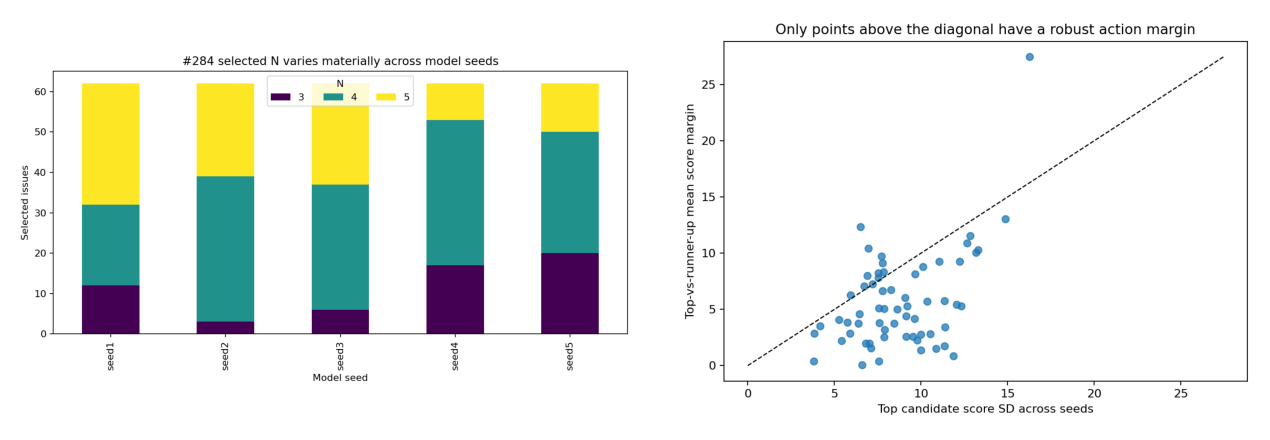

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
img1 = plt.imread(RESULTS / 'parameter_reliability_n.png')
img2 = plt.imread(RESULTS / 'parameter_reliability_margin_vs_seed_sd.png')
axes[0].imshow(img1); axes[0].axis('off')
axes[1].imshow(img2); axes[1].axis('off')
plt.tight_layout()

## Multi-subset aggregation and the N curve

In [4]:
summary=[]
for n, group in issue_n.groupby('n'):
    group=group.sort_values(['issue_year','issue'])
    pnl=group.realized_mean.to_numpy(float)
    capital=100_000+np.cumsum(pnl)
    peak=np.maximum.accumulate(np.r_[100_000,capital])[:-1]
    years=group.groupby('issue_year').realized_mean.mean()
    summary.append({
        'N': int(n), 'mean_roi_pct': pnl.mean(), 'median_issue_roi': np.median(pnl),
        'positive_issue_fraction': (pnl>0).mean(), 'positive_years': int((years>0).sum()),
        'max_drawdown': float(((peak-capital)/peak).max()),
    })
n_curve=pd.DataFrame(summary)
n_curve

,N,mean_roi_pct,median_issue_roi,positive_issue_fraction,positive_years,max_drawdown
0,3,-28.701637,-28.752887,0.012903,0,0.177950
1,4,-25.767943,-25.827537,0.022581,0,0.159761
2,5,-22.017334,-23.157007,0.137097,0,0.136507
3,6,-19.094253,-26.135121,0.269355,0,0.119751
4,7,-10.304970,-27.177943,0.341935,2,0.068542
5,8,-10.692470,-60.350192,0.289176,3,0.079839
6,9,-6.535292,-100.000000,0.248788,3,0.060248
7,10,-14.923134,-100.000000,0.113086,3,0.141767


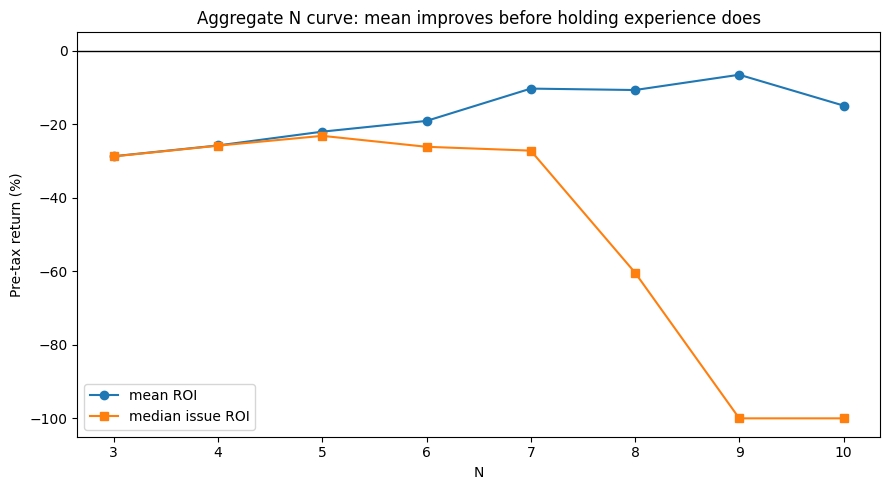

In [5]:
fig, ax1=plt.subplots(figsize=(9,5))
ax1.plot(n_curve.N,n_curve.mean_roi_pct,marker='o',label='mean ROI')
ax1.plot(n_curve.N,n_curve.median_issue_roi,marker='s',label='median issue ROI')
ax1.axhline(0,color='black',linewidth=1)
ax1.set(xlabel='N',ylabel='Pre-tax return (%)',title='Aggregate N curve: mean improves before holding experience does')
ax1.legend(); plt.tight_layout()

N9 has the best aggregate mean, but its median issue loses the
full risk budget. High N therefore behaves like a sparse-jackpot sleeve, not a
uniformly better action.

## Expanding-window residual learning, 2018–2023

In [6]:
metrics.sort_values('mean_roi_pct', ascending=False)

,policy,issues,mean_roi_pct,ending_capital_cny,matched_lift_cny100,ex_largest_matched_lift_cny100,positive_lift_years,max_drawdown_fraction,selected_n_entropy
0,EXPECTED_ONLY,328,0.659995,100216.478303,5330.909590,-4599.476144,2,0.080037,0.547198
1,FIXED_N7,328,-15.592778,94885.568714,0.000000,0.000000,0,0.051144,-0.000000
3,N_PRIOR,328,-16.677897,94529.649836,-355.918878,-3576.695687,3,0.071547,1.276374
2,HIST_GB,328,-23.321437,92350.568695,-2535.000019,-5755.776828,1,0.076527,1.466678
4,RIDGE,328,-27.329856,91035.807205,-3849.761509,-4654.028467,3,0.090039,1.620271


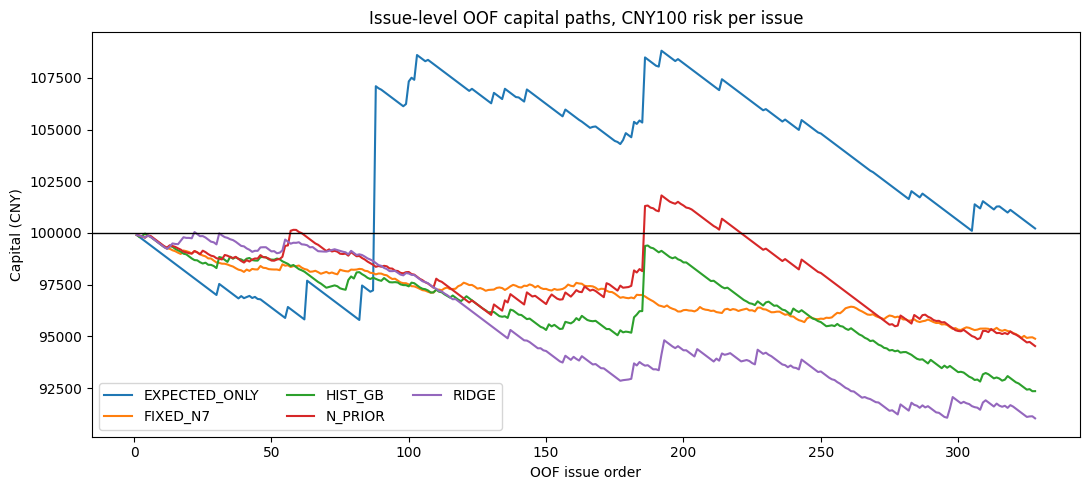

In [7]:
fig, ax=plt.subplots(figsize=(11,5))
for policy, group in oof.groupby('policy'):
    group=group.sort_values(['issue_year','issue'])
    capital=100_000+group.realized_mean.cumsum()
    ax.plot(range(1,len(group)+1),capital,label=policy)
ax.axhline(100_000,color='black',linewidth=1)
ax.set(xlabel='OOF issue order',ylabel='Capital (CNY)',title='Issue-level OOF capital paths, CNY100 risk per issue')
ax.legend(ncol=3); plt.tight_layout()

## Decision

Direct expected-value enumeration is the only positive-mean OOF path, but one
2019 N10 jackpot dominates it; ex-largest lift is negative and only two of six
years beat N7. Ridge and histogram gradient boosting cannot predict the
realized residual and degrade the capital path.

**Verdict:** the expected N frontier is computable, but issue-specific realized
parameter selection is not yet reliable. Keep explicit N enumeration and an
uncertainty/abstention boundary. The follow-up joint screen therefore expands a
bounded `N × K × generator × subset` action space with nuisance replication;
it does not treat a one-off realized winner as the training target.